# Federated Learning on ISIC 2019 — 9 CNN / Transformer backbones
ResNet50 · DenseNet121 · EfficientNet-B0 · VGG16 · InceptionV3 · MobileNetV3 · ConvNeXt-Tiny · ViT-B/16 · Swin-T

PyTorch + Flower 1.39 (simulation, Message API), FedAvg.
Dataset: Kaggle `salviohexia/isic-2019-skin-lesion-images-for-classification` (25,331 images, 8 classes)

Runs in a VS Code Jupyter notebook with the Anaconda kernel `fl-isic` (see environment.yml).
Images are read directly from LOCAL_DATA_DIR on your PC.

Pipeline: dataset discovery -> 256px cache -> stratified split (train 70 / server-val 10 / test 20)
-> Dirichlet non-IID client partition -> FedAvg for every model in MODELS (one after another, one run)
-> best round chosen on server-val -> final held-out test report and comparison of all models.

Every round prints, for each client, the LOCAL model (after local training, before aggregation)
and the new GLOBAL model (after FedAvg), plus the GLOBAL model on the server-val set.
First run a smoke test with SUBSET_FRACTION = 0.1 and NUM_ROUNDS = 2.

## 1. Imports

In [1]:
import os, sys, gc, math, json, time, random, warnings, logging, traceback
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import seaborn as sns
from PIL import Image, ImageFile
from tqdm.auto import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             roc_auc_score, classification_report, confusion_matrix,
                             roc_curve, auc)

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms

import flwr
from flwr.app import ArrayRecord, ConfigRecord, Context, Message, MetricRecord, RecordDict
from flwr.clientapp import ClientApp
from flwr.serverapp import Grid, ServerApp
from flwr.serverapp.strategy import FedAvg
from flwr.simulation import run_simulation
from flwr.common.logger import FLOWER_LOGGER

ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore", category=UserWarning)

print(f"Python {sys.version.split()[0]} | torch {torch.__version__} | "
      f"torchvision {__import__('torchvision').__version__} | flwr {flwr.__version__}")
print("CUDA available:", torch.cuda.is_available(),
      "|", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU only")

Python 3.11.16 | torch 2.9.1+cu126 | torchvision 0.24.1+cu126 | flwr 1.39.0
CUDA available: True | NVIDIA GeForce RTX 4090


## 2. Configuration — edit only this cell

In [2]:
# ---------- Dataset location ----------
# Folder where you unzipped the Kaggle dataset (any sub-folder layout is fine)
LOCAL_DATA_DIR = r"F:\Rakib\dataset"

# ---------- Output ----------
OUTPUT_DIR = Path("./fl_isic_outputs_version2")   # checkpoints, histories, figures (next to the notebook)
CACHE_DIR  = Path("./isic_cache_256_version2")    # resized copy of the images (~1 GB, created once)

# ---------- Models (all trained in one run, one after another) ----------
MODELS = [
    "resnet50",            # ResNet50
    "densenet121",         # DenseNet121
    "efficientnet_b0",     # EfficientNet-B0
    "vgg16",               # VGG16           (138M params: heaviest in memory)
    "inception_v3",        # InceptionV3
    "mobilenet_v3_large",  # MobileNetV3-Large
    "convnext_tiny",       # ConvNeXt-Tiny
    "vit_b_16",            # ViT-B/16        (needs exactly 224x224 input)
    "swin_t",              # Swin Transformer-T
]
PRETRAINED = True               # ImageNet weights (strongly recommended)
SKIP_COMPLETED = True           # skip a model whose results already exist in OUTPUT_DIR (resume after a crash)

# ---------- Data ----------
SUBSET_FRACTION = 1.0           # quick test: 0.1 (stratified subset of the whole dataset)
IMG_SIZE   = 224                # same input size for every model (ViT-B/16 requires 224)
CACHE_SIZE = 256                # images are resized once (shorter side) -> much faster training
VAL_FRAC, TEST_FRAC = 0.10, 0.20
LOCAL_VAL_FRAC = 0.10           # each client keeps 10% of its data for local validation

# ---------- Federated setup ----------
NUM_CLIENTS     = 5
PARTITION       = "dirichlet"   # "dirichlet" (non-IID) or "iid"
DIRICHLET_ALPHA = 0.5           # smaller = more heterogeneous
NUM_ROUNDS      = 10
LOCAL_EPOCHS    = 10
FRACTION_TRAIN  = 1.0           # fraction of clients sampled per round
FRACTION_EVAL   = 1.0           # global model evaluated on every client's local val (0.0 = skip)

# ---------- Optimisation ----------
BATCH_SIZE   = 32
LR, LR_MIN   = 1e-4, 1e-6       # AdamW, cosine decay over rounds
MODEL_LR     = {"vit_b_16": 3e-5, "swin_t": 5e-5}   # transformers fine-tune better with a lower LR
BATCH_SIZE_OVERRIDE = {}        # if a model runs out of GPU memory, e.g. {"vgg16": 16, "vit_b_16": 16}
WEIGHT_DECAY = 1e-4
USE_CLASS_WEIGHTS = True        # ISIC 2019 is highly imbalanced (NV >> DF, VASC)
USE_AMP = True                  # mixed precision on GPU

# ---------- Logging ----------
QUIET_FLOWER_LOGS = True        # hide Flower's INFO logs; show our own per-round summary instead
PRINT_CLIENT_DETAILS = True     # one line per client per round (local vs global model)

# ---------- Hardware (Ray resources per virtual client) ----------
NUM_GPUS = torch.cuda.device_count()
CLIENT_NUM_GPUS = 1.0 if NUM_GPUS else 0.0   # 1.0 = clients train one at a time on the GPU (safest)
CLIENT_NUM_CPUS = max(1, min(4, os.cpu_count() or 1))
NUM_WORKERS = 0 if os.name == "nt" else min(2, CLIENT_NUM_CPUS)  # Windows: 0 (spawn-safe)

SEED = 42

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
seed_everything()

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FLOWER_LOGGER.setLevel(logging.WARNING if QUIET_FLOWER_LOGS else logging.INFO)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| GPUs:", NUM_GPUS, "| CPUs:", os.cpu_count())

Device: cuda | GPUs: 1 | CPUs: 32


## 3. Locate the dataset

In [3]:
def locate_dataset() -> Path:
    """Return the dataset root folder on the local disk."""
    p = Path(LOCAL_DATA_DIR).expanduser()
    if not p.exists():
        raise FileNotFoundError(f"LOCAL_DATA_DIR not found: {p}")
    return p

DATA_ROOT = locate_dataset()
print("Dataset root:", DATA_ROOT)

Dataset root: F:\Rakib\dataset


## 4. Dataset discovery (folder-per-class or ISIC ground-truth CSV, auto-detected)

25331 images | 8 classes: ['AK', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'SCC', 'VASC']


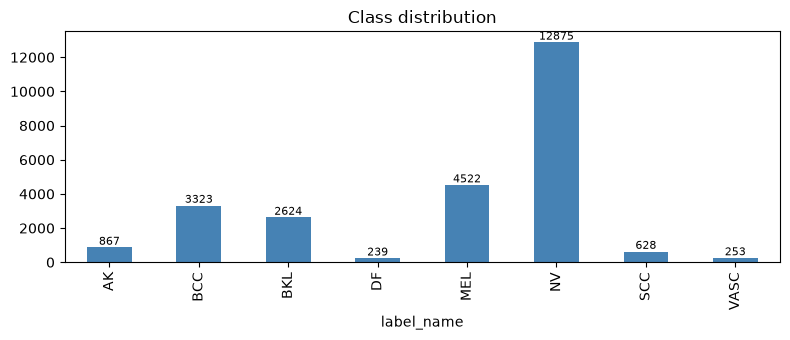

In [4]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def discover_dataset(root: Path) -> pd.DataFrame:
    """Return DataFrame[path, label_name]. Supports
    (a) class sub-folders at any depth (train/val/test split folders are merged) and
    (b) ISIC_2019_Training_GroundTruth.csv (one-hot) + an image folder."""
    files = [p for p in root.rglob("*") if p.suffix.lower() in IMG_EXTS]
    if not files:
        raise RuntimeError(f"No images found under {root}")

    csvs = [c for c in root.rglob("*.csv") if "groundtruth" in c.name.lower()]
    parents = pd.Series([p.parent.name for p in files])
    if csvs and parents.nunique() < 3:          # (b) CSV layout
        gt = pd.read_csv(csvs[0])
        cls_cols = [c for c in gt.columns if c != "image" and c != "UNK" and gt[c].sum() > 0]
        gt["label_name"] = gt[cls_cols].idxmax(axis=1)
        by_stem = {p.stem: str(p.resolve()) for p in files}
        gt["path"] = gt["image"].map(by_stem)
        df = gt.dropna(subset=["path"])[["path", "label_name"]]
    else:                                        # (a) folder-per-class layout
        df = pd.DataFrame({"path": [str(p.resolve()) for p in files],
                           "label_name": parents.values})
    # Drop duplicate files (same file name appearing in several split folders)
    df["stem"] = df["path"].map(lambda s: Path(s).stem)
    df = df.drop_duplicates(subset=["stem", "label_name"]).drop(columns="stem")
    return df.reset_index(drop=True)

df_all = discover_dataset(DATA_ROOT)
CLASS_NAMES = sorted(df_all["label_name"].unique())
NUM_CLASSES = len(CLASS_NAMES)
df_all["label"] = df_all["label_name"].map({c: i for i, c in enumerate(CLASS_NAMES)})
print(f"{len(df_all)} images | {NUM_CLASSES} classes: {CLASS_NAMES}")

if SUBSET_FRACTION < 1.0:
    df_all, _ = train_test_split(df_all, train_size=SUBSET_FRACTION,
                                 stratify=df_all["label"], random_state=SEED)
    df_all = df_all.reset_index(drop=True)
    print(f"Using stratified subset: {len(df_all)} images")

counts = df_all["label_name"].value_counts().reindex(CLASS_NAMES)
ax = counts.plot.bar(figsize=(8, 3.5), color="steelblue", title="Class distribution")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "class_distribution.png", dpi=150); plt.show()

## 5. One-time resize cache (256px)
Many ISIC images are 1024px+; decoding them every epoch is slow. Done once, skipped on later runs.

In [5]:
def cache_one(args):
    """Resize one image (shorter side -> CACHE_SIZE) and save it as JPEG in CACHE_DIR."""
    src, dst = args
    if dst.exists():
        return
    try:
        with Image.open(src) as im:
            im = im.convert("RGB")
            w, h = im.size
            s = CACHE_SIZE / min(w, h)
            if s < 1:
                im = im.resize((max(1, round(w * s)), max(1, round(h * s))), Image.BICUBIC)
            dst.parent.mkdir(parents=True, exist_ok=True)
            im.save(dst, "JPEG", quality=95)
    except Exception as e:
        print("Failed:", src, e)

jobs = [(Path(p), CACHE_DIR / ln / (Path(p).stem + ".jpg"))
        for p, ln in zip(df_all["path"], df_all["label_name"])]
with ThreadPoolExecutor(max_workers=max(4, (os.cpu_count() or 2) * 2)) as ex:
    list(tqdm(ex.map(cache_one, jobs), total=len(jobs), desc="Caching"))
df_all["path"] = [str(d.resolve()) for _, d in jobs]
df_all = df_all[df_all["path"].map(os.path.exists)].reset_index(drop=True)
print("Cached images:", len(df_all), "->", CACHE_DIR.resolve())

Caching:   0%|          | 0/25331 [00:00<?, ?it/s]

Cached images: 25331 -> F:\Rakib\isic_cache_256_version2


## 6. Split (train / server-val / test) and client partition (non-IID)
- server-val: evaluates the global model every round and selects the best round.
- test: used only once at the end, for the reported results (no selection bias).

train 17731 | server-val 2533 | test 5067
Client 0: 2927 train | 326 local-val
Client 1: 1570 train | 175 local-val
Client 2: 5296 train | 589 local-val
Client 3: 1620 train | 181 local-val
Client 4: 4542 train | 505 local-val


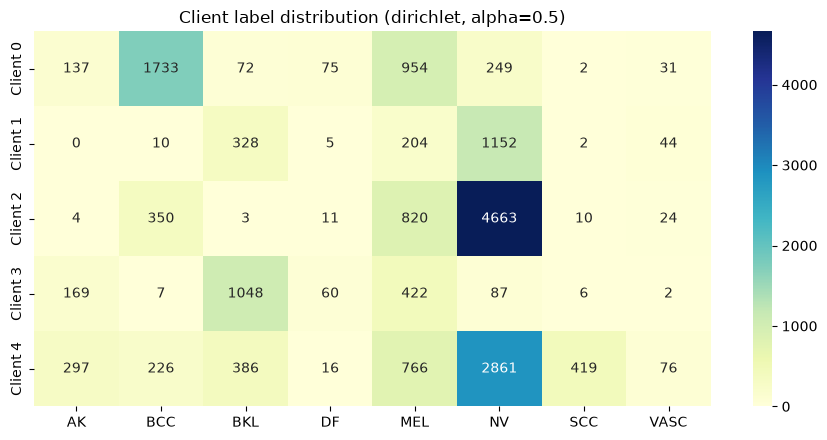

In [6]:
df_trainpool, df_test = train_test_split(df_all, test_size=TEST_FRAC,
                                         stratify=df_all["label"], random_state=SEED)
df_train, df_val = train_test_split(df_trainpool, test_size=VAL_FRAC / (1 - TEST_FRAC),
                                    stratify=df_trainpool["label"], random_state=SEED)
df_train, df_val, df_test = (d.reset_index(drop=True) for d in (df_train, df_val, df_test))
print(f"train {len(df_train)} | server-val {len(df_val)} | test {len(df_test)}")

def partition_indices(labels: np.ndarray, n_clients: int, method: str, alpha: float,
                      seed: int = SEED, min_size: int = 20):
    """Split sample indices among clients: IID, or Dirichlet label-skew (non-IID)."""
    rng = np.random.default_rng(seed)
    if method == "iid":
        idx = rng.permutation(len(labels))
        return [p.tolist() for p in np.array_split(idx, n_clients)]
    for _ in range(1000):                       # retry until every client has >= min_size samples
        parts = [[] for _ in range(n_clients)]
        for c in np.unique(labels):
            idx_c = rng.permutation(np.where(labels == c)[0])
            props = rng.dirichlet(alpha * np.ones(n_clients))
            cuts = (np.cumsum(props) * len(idx_c)).astype(int)[:-1]
            for k, chunk in enumerate(np.split(idx_c, cuts)):
                parts[k].extend(chunk.tolist())
        if min(len(p) for p in parts) >= min_size:
            return parts
    raise RuntimeError("Could not create partitions; increase alpha or reduce NUM_CLIENTS")

parts = partition_indices(df_train["label"].values, NUM_CLIENTS, PARTITION, DIRICHLET_ALPHA)
CLIENT_DATA = []   # per client: (train_records, localval_records); records = list[(path, label)]
for k, idx in enumerate(parts):
    d = df_train.iloc[idx]
    vc = d["label"].value_counts()
    strat = d["label"] if vc.min() >= 2 and int(len(d) * LOCAL_VAL_FRAC) >= len(vc) else None
    tr, va = train_test_split(d, test_size=LOCAL_VAL_FRAC, stratify=strat, random_state=SEED)
    CLIENT_DATA.append((list(zip(tr["path"], tr["label"])), list(zip(va["path"], va["label"]))))
for k, (tr, va) in enumerate(CLIENT_DATA):
    print(f"Client {k}: {len(tr)} train | {len(va)} local-val")

# Heatmap of samples per class per client
mat = np.zeros((NUM_CLIENTS, NUM_CLASSES), dtype=int)
for k, idx in enumerate(parts):
    for c, n in df_train.iloc[idx]["label"].value_counts().items():
        mat[k, c] = n
plt.figure(figsize=(9, 0.6 * NUM_CLIENTS + 1.5))
sns.heatmap(mat, annot=True, fmt="d", cmap="YlGnBu", xticklabels=CLASS_NAMES,
            yticklabels=[f"Client {k}" for k in range(NUM_CLIENTS)])
plt.title(f"Client label distribution ({PARTITION}, alpha={DIRICHLET_ALPHA})")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "client_partition.png", dpi=150); plt.show()

## 7. PyTorch Dataset and transforms

In [7]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)   # ImageNet statistics (all 9 models)
TRAIN_TF = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(), transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.02),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])
EVAL_TF = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 256 / 224)), transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class ISICDataset(Dataset):
    """Dataset over a list of (image_path, label) records."""
    def __init__(self, records, tf):
        self.records, self.tf = records, tf
    def __len__(self):
        return len(self.records)
    def __getitem__(self, i):
        path, label = self.records[i]
        with Image.open(path) as im:
            x = self.tf(im.convert("RGB"))
        return x, int(label)

def make_loader(records, train: bool, batch_size: int = BATCH_SIZE):
    return DataLoader(ISICDataset(records, TRAIN_TF if train else EVAL_TF),
                      batch_size=batch_size, shuffle=train,
                      drop_last=train and len(records) > batch_size,
                      num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available(),
                      persistent_workers=False)

VAL_RECORDS  = list(zip(df_val["path"], df_val["label"]))
TEST_RECORDS = list(zip(df_test["path"], df_test["label"]))

## 8. Model zoo — 9 ImageNet-pretrained backbones from torchvision

In [8]:
# name -> (display name, constructor, ImageNet weights)
MODEL_ZOO = {
    "resnet50":           ("ResNet50",          models.resnet50,           models.ResNet50_Weights.IMAGENET1K_V2),
    "densenet121":        ("DenseNet121",       models.densenet121,        models.DenseNet121_Weights.IMAGENET1K_V1),
    "efficientnet_b0":    ("EfficientNet-B0",   models.efficientnet_b0,    models.EfficientNet_B0_Weights.IMAGENET1K_V1),
    "vgg16":              ("VGG16",             models.vgg16,              models.VGG16_Weights.IMAGENET1K_V1),
    "inception_v3":       ("InceptionV3",       models.inception_v3,       models.Inception_V3_Weights.IMAGENET1K_V1),
    "mobilenet_v3_large": ("MobileNetV3-Large", models.mobilenet_v3_large, models.MobileNet_V3_Large_Weights.IMAGENET1K_V2),
    "convnext_tiny":      ("ConvNeXt-Tiny",     models.convnext_tiny,      models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1),
    "vit_b_16":           ("ViT-B/16",          models.vit_b_16,           models.ViT_B_16_Weights.IMAGENET1K_V1),
    "swin_t":             ("Swin-T",            models.swin_t,             models.Swin_T_Weights.IMAGENET1K_V1),
}
DISPLAY = {k: v[0] for k, v in MODEL_ZOO.items()}

def build_model(name: str, num_classes: int, pretrained: bool = False) -> nn.Module:
    """Build a backbone and replace its classification head with num_classes outputs.
    The architecture must be identical with and without pretrained weights, because clients
    build the model without weights and then load the global weights sent by the server."""
    _, ctor, weights = MODEL_ZOO[name]
    w = weights if pretrained else None
    if name == "inception_v3":
        # Pretrained InceptionV3 requires aux_logits=True; drop the auxiliary head afterwards so
        # forward() returns plain logits. transform_input is fixed so both builds behave the same.
        m = ctor(weights=w, aux_logits=True, transform_input=True, init_weights=(w is None))
        m.aux_logits, m.AuxLogits = False, None
    else:
        m = ctor(weights=w)

    if name in ("resnet50", "inception_v3"):
        m.fc = nn.Linear(m.fc.in_features, num_classes)
    elif name == "densenet121":
        m.classifier = nn.Linear(m.classifier.in_features, num_classes)
    elif name == "efficientnet_b0":
        m.classifier[1] = nn.Linear(m.classifier[1].in_features, num_classes)
    elif name == "vgg16":
        m.classifier[6] = nn.Linear(m.classifier[6].in_features, num_classes)
    elif name == "mobilenet_v3_large":
        m.classifier[3] = nn.Linear(m.classifier[3].in_features, num_classes)
    elif name == "convnext_tiny":
        m.classifier[2] = nn.Linear(m.classifier[2].in_features, num_classes)
    elif name == "vit_b_16":
        m.heads.head = nn.Linear(m.heads.head.in_features, num_classes)
    elif name == "swin_t":
        m.head = nn.Linear(m.head.in_features, num_classes)
    return m

def model_lr(name):
    return MODEL_LR.get(name, LR)

def model_batch(name):
    return BATCH_SIZE_OVERRIDE.get(name, BATCH_SIZE)

# Download all pretrained weights once in the main process (clients receive them from the server)
for name in MODELS:
    m = build_model(name, NUM_CLASSES, PRETRAINED)
    print(f"{DISPLAY[name]:18s} params: {sum(p.numel() for p in m.parameters())/1e6:6.1f}M | "
          f"lr {model_lr(name):.0e} | batch {model_batch(name)}")
    del m
gc.collect()

ResNet50           params:   23.5M | lr 1e-04 | batch 32
DenseNet121        params:    7.0M | lr 1e-04 | batch 32
EfficientNet-B0    params:    4.0M | lr 1e-04 | batch 32
VGG16              params:  134.3M | lr 1e-04 | batch 32
InceptionV3        params:   21.8M | lr 1e-04 | batch 32
MobileNetV3-Large  params:    4.2M | lr 1e-04 | batch 32
Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to C:\Users\USER/.cache\torch\hub\checkpoints\convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:02<00:00, 45.5MB/s] 


ConvNeXt-Tiny      params:   27.8M | lr 1e-04 | batch 32
ViT-B/16           params:   85.8M | lr 3e-05 | batch 32
Swin-T             params:   27.5M | lr 5e-05 | batch 32


6475

## 9. Training / evaluation helpers and metrics

In [9]:
def class_weights_from(records, num_classes):
    """Square-root inverse-frequency class weights from a client's local labels."""
    counts = np.bincount([l for _, l in records], minlength=num_classes).astype(float)
    w = np.where(counts > 0, np.sqrt(counts.sum() / (num_classes * np.maximum(counts, 1))), 0.0)
    w = w / w[counts > 0].mean()
    return torch.tensor(w, dtype=torch.float32)

def train_local(model, loader, epochs, lr, device, class_weights=None):
    """Local client training; returns (mean training loss, training accuracy).
    Training accuracy is measured on the augmented mini-batches seen during training."""
    model.to(device).train()
    crit = nn.CrossEntropyLoss(weight=class_weights.to(device) if class_weights is not None else None,
                               label_smoothing=0.05)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=WEIGHT_DECAY)
    amp = USE_AMP and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp)
    total, correct, n = 0.0, 0, 0
    for _ in range(epochs):
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            opt.zero_grad(set_to_none=True)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
                out = model(x)
                loss = crit(out, y)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            total += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            n += y.size(0)
    return total / max(n, 1), correct / max(n, 1)

@torch.no_grad()
def predict(model, loader, device):
    """Return (mean loss, true labels, softmax probabilities)."""
    model.to(device).eval()
    amp = USE_AMP and device.type == "cuda"
    crit = nn.CrossEntropyLoss(reduction="sum")
    loss, ys, ps = 0.0, [], []
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=amp):
            out = model(x)
        loss += crit(out.float(), y).item()
        ys.append(y.cpu()); ps.append(torch.softmax(out.float(), 1).cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(ps).numpy()
    return loss / len(y), y, p

def compute_metrics(y, prob, num_classes):
    pred = prob.argmax(1)
    m = {"acc": accuracy_score(y, pred),
         "bal_acc": balanced_accuracy_score(y, pred),      # official ISIC 2019 metric
         "f1_macro": f1_score(y, pred, average="macro", zero_division=0)}
    try:
        m["auc_macro"] = roc_auc_score(y, prob, multi_class="ovr", average="macro",
                                       labels=list(range(num_classes)))
    except ValueError:
        m["auc_macro"] = float("nan")
    return m

def cosine_lr(server_round, num_rounds, base_lr):
    """Learning rate for a given round: cosine decay from base_lr to LR_MIN."""
    t = (server_round - 1) / max(1, num_rounds - 1)
    return LR_MIN + 0.5 * (base_lr - LR_MIN) * (1 + math.cos(math.pi * t))

## 10. Flower ClientApp (Message API)
- train: receives the GLOBAL model, trains it locally -> LOCAL model. Reports the LOCAL model's
  training loss/acc and its accuracy on the client's own local-val split, then returns its weights.
- evaluate: receives the NEW GLOBAL model (after FedAvg) and evaluates it on the same local-val split,
  so local and global performance can be compared on identical data.
The server sends the model name in the config, so one ClientApp serves all models.

In [10]:
client_app = ClientApp()

def _device():
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")

def _load_global(msg):
    cfg = msg.content["config"]
    model = build_model(str(cfg["model-name"]), NUM_CLASSES, pretrained=False)
    model.load_state_dict(msg.content["arrays"].to_torch_state_dict())
    return model, cfg

@client_app.train()
def client_train(msg: Message, context: Context):
    pid = int(context.node_config["partition-id"])
    device = _device()
    model, cfg = _load_global(msg)
    train_records, val_records = CLIENT_DATA[pid]
    bs = int(cfg["batch-size"])

    # Local training: global model -> local model
    lr = cosine_lr(int(cfg["server-round"]), int(cfg["num-rounds"]), float(cfg["base-lr"]))
    cw = class_weights_from(train_records, NUM_CLASSES) if USE_CLASS_WEIGHTS else None
    tr_loss, tr_acc = train_local(model, make_loader(train_records, True, bs),
                                  int(cfg["local-epochs"]), lr, device, cw)

    # Local model on the client's own local-val split (before aggregation)
    va_loss, y, p = predict(model, make_loader(val_records, False, bs), device)

    # "num-examples" is the FedAvg weight; "partition-id" lets the server report per client
    content = RecordDict({
        "arrays": ArrayRecord(model.state_dict()),
        "metrics": MetricRecord({
            "partition-id": pid,
            "local_train_loss": tr_loss, "local_train_acc": tr_acc,
            "local_val_loss": va_loss, "local_val_acc": float((p.argmax(1) == y).mean()),
            "num-examples": len(train_records)}),
    })
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return Message(content=content, reply_to=msg)

@client_app.evaluate()
def client_evaluate(msg: Message, context: Context):
    pid = int(context.node_config["partition-id"])
    device = _device()
    model, cfg = _load_global(msg)
    _, val_records = CLIENT_DATA[pid]

    # New global model on this client's local-val split
    loss, y, p = predict(model, make_loader(val_records, False, int(cfg["batch-size"])), device)
    content = RecordDict({"metrics": MetricRecord({
        "partition-id": pid,
        "global_val_loss": loss, "global_val_acc": float((p.argmax(1) == y).mean()),
        "num-examples": len(val_records)})})
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return Message(content=content, reply_to=msg)

## 11. Flower ServerApp — FedAvg + per-round reporting (local vs global) + best-model checkpoint

In [11]:
HISTORY = {}         # model -> list of per-round GLOBAL metrics (filled by the ServerApp thread)
CLIENT_HISTORY = {}  # model -> list of per-round, per-client rows (LOCAL and GLOBAL on client data)

def _collect(records, weight_key):
    """Per-client metric rows + weighted average (FedAvg weighting) of every metric."""
    rows = []
    for rec in records:
        mr = next(iter(rec.metric_records.values()))
        rows.append({k: float(v) for k, v in mr.items()})
    rows.sort(key=lambda r: r["partition-id"])
    w = np.array([r[weight_key] for r in rows], dtype=float)
    w = w / w.sum()
    keys = [k for k in rows[0] if k not in ("partition-id", weight_key)]
    avg = {k: float(sum(wi * r[k] for wi, r in zip(w, rows))) for k in keys}
    return rows, avg

def make_server_app(model_name: str) -> ServerApp:
    server_app = ServerApp()
    label = DISPLAY[model_name]

    @server_app.main()
    def main(grid: Grid, context: Context) -> None:
        init_model = build_model(model_name, NUM_CLASSES, pretrained=PRETRAINED)
        eval_model = build_model(model_name, NUM_CLASSES, pretrained=False)
        val_loader = make_loader(VAL_RECORDS, train=False)
        HISTORY[model_name], CLIENT_HISTORY[model_name] = [], []
        best = {"bal_acc": -1.0, "round": 0}
        round_stats = {}   # client-side results of the current round
        t0 = time.time()

        def train_aggr(records, weight_key):
            """Called by FedAvg after local training: keep per-client LOCAL-model metrics."""
            rows, avg = _collect(records, weight_key)
            round_stats["local"] = (rows, avg)
            return MetricRecord(avg)

        def eval_aggr(records, weight_key):
            """Called by FedAvg after client evaluation: keep per-client GLOBAL-model metrics."""
            rows, avg = _collect(records, weight_key)
            round_stats["global_on_clients"] = (rows, avg)
            return MetricRecord(avg)

        def central_evaluate(server_round: int, arrays: ArrayRecord) -> MetricRecord:
            """Runs last in every round: evaluate the new GLOBAL model on server-val and print the summary."""
            eval_model.load_state_dict(arrays.to_torch_state_dict())
            loss, y, p = predict(eval_model, val_loader, DEVICE)
            eval_model.cpu()   # free GPU memory for the clients
            m = compute_metrics(y, p, NUM_CLASSES)
            m.update(round=server_round, val_loss=loss, elapsed_min=(time.time() - t0) / 60)

            local_rows, local_avg = round_stats.pop("local", ([], {}))
            glob_rows, glob_avg = round_stats.pop("global_on_clients", ([], {}))
            if server_round > 0 and not local_rows:
                raise RuntimeError(
                    f"[{label}] all clients failed in round {server_round} (usually out of GPU memory or RAM). "
                    f"Try BATCH_SIZE_OVERRIDE = {{'{model_name}': 16}} and re-run this cell.")

            nan = float("nan")
            m.update(local_train_loss=local_avg.get("local_train_loss", nan),
                     local_train_acc=local_avg.get("local_train_acc", nan),
                     local_val_acc=local_avg.get("local_val_acc", nan),
                     global_client_val_acc=glob_avg.get("global_val_acc", nan))
            if server_round > 0 and m["bal_acc"] > best["bal_acc"]:
                best.update(bal_acc=m["bal_acc"], round=server_round)
                torch.save(eval_model.state_dict(), OUTPUT_DIR / f"{model_name}_best.pt")
            HISTORY[model_name].append(m)

            # Per-client rows: LOCAL model vs new GLOBAL model on the same client data
            g_by_pid = {int(r["partition-id"]): r for r in glob_rows}
            for r in local_rows:
                pid = int(r["partition-id"])
                g = g_by_pid.get(pid, {})
                CLIENT_HISTORY[model_name].append({
                    "round": server_round, "client": pid, "n_train": int(r["num-examples"]),
                    "local_train_loss": r["local_train_loss"], "local_train_acc": r["local_train_acc"],
                    "local_val_acc": r["local_val_acc"], "global_val_acc": g.get("global_val_acc", nan)})

            # ---------- Console summary ----------
            if server_round == 0:
                print(f"\n[{label}] Round 0/{NUM_ROUNDS} (initial global model, before training)")
            else:
                print(f"\n[{label}] Round {server_round}/{NUM_ROUNDS}  ({m['elapsed_min']:.1f} min)")
                if PRINT_CLIENT_DETAILS:
                    for row in CLIENT_HISTORY[model_name][-len(local_rows):]:
                        print(f"   Client {row['client']} (n={row['n_train']:5d}) | "
                              f"LOCAL  train_loss {row['local_train_loss']:.4f}  train_acc {row['local_train_acc']:.4f}  "
                              f"val_acc {row['local_val_acc']:.4f} | GLOBAL val_acc {row['global_val_acc']:.4f}")
                print(f"   LOCAL  models (weighted mean)  | train_loss {m['local_train_loss']:.4f}  "
                      f"train_acc {m['local_train_acc']:.4f}  val_acc {m['local_val_acc']:.4f}")
                print(f"   GLOBAL model on client val     | val_acc {m['global_client_val_acc']:.4f}")
            print(f"   GLOBAL model on server-val     | loss {loss:.4f}  acc {m['acc']:.4f}  "
                  f"bal_acc {m['bal_acc']:.4f}  f1 {m['f1_macro']:.4f}  auc {m['auc_macro']:.4f}"
                  + ("   <- best so far, saved" if server_round > 0 and best["round"] == server_round else ""))
            return MetricRecord({k: float(v) for k, v in m.items()})

        strategy = FedAvg(fraction_train=FRACTION_TRAIN, fraction_evaluate=FRACTION_EVAL,
                          min_train_nodes=max(1, int(FRACTION_TRAIN * NUM_CLIENTS)),
                          min_evaluate_nodes=max(1, int(FRACTION_EVAL * NUM_CLIENTS)) if FRACTION_EVAL > 0 else 1,
                          min_available_nodes=NUM_CLIENTS,
                          train_metrics_aggr_fn=train_aggr,
                          evaluate_metrics_aggr_fn=eval_aggr)
        cfg = {"model-name": model_name, "batch-size": model_batch(model_name)}
        result = strategy.start(
            grid=grid,
            initial_arrays=ArrayRecord(init_model.state_dict()),
            num_rounds=NUM_ROUNDS,
            train_config=ConfigRecord({**cfg, "local-epochs": LOCAL_EPOCHS, "num-rounds": NUM_ROUNDS,
                                       "base-lr": model_lr(model_name)}),
            evaluate_config=ConfigRecord(cfg),
            evaluate_fn=central_evaluate,
        )
        torch.save(result.arrays.to_torch_state_dict(), OUTPUT_DIR / f"{model_name}_final.pt")
        print(f"\n[{label}] best server-val bal_acc {best['bal_acc']:.4f} at round {best['round']}")

    return server_app

## 12. Run the simulation — all models in one run, one after another
A model that fails (e.g. CUDA out of memory) is reported and skipped; the run continues with the next.
With SKIP_COMPLETED = True, re-running this cell after a crash resumes from the first unfinished model.

In [12]:
backend_config = {
    "client_resources": {"num_cpus": CLIENT_NUM_CPUS, "num_gpus": CLIENT_NUM_GPUS},
    "init_args": {"include_dashboard": False, "log_to_driver": True},
}

def is_completed(name):
    return ((OUTPUT_DIR / f"{name}_history.json").exists()
            and (OUTPUT_DIR / f"{name}_best.pt").exists())

FAILED = {}
run_t0 = time.time()
for i, model_name in enumerate(MODELS, 1):
    title = f" [{i}/{len(MODELS)}] Federated training: {DISPLAY[model_name]} "
    print("\n" + title.center(100, "="))
    if SKIP_COMPLETED and is_completed(model_name):
        print("Results already in OUTPUT_DIR -> skipped (set SKIP_COMPLETED = False to retrain).")
        continue
    seed_everything()
    try:
        run_simulation(server_app=make_server_app(model_name), client_app=client_app,
                       num_supernodes=NUM_CLIENTS, backend_config=backend_config)
        with open(OUTPUT_DIR / f"{model_name}_history.json", "w") as f:
            json.dump(HISTORY[model_name], f, indent=2)
        pd.DataFrame(CLIENT_HISTORY[model_name]).to_csv(
            OUTPUT_DIR / f"{model_name}_client_metrics.csv", index=False)
    except Exception as e:
        FAILED[model_name] = str(e)
        print(f"!! {DISPLAY[model_name]} FAILED: {e}")
        traceback.print_exc(limit=1)
    finally:
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

print(f"\nAll models finished in {(time.time() - run_t0) / 60:.1f} min. Failed: {list(FAILED) or 'none'}")


            This is a deprecated feature. It will be removed
            entirely in future versions of Flower.
        



================================ [1/9] Federated training: ResNet50 ================================


c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\ray\_private\worker.py:2051: FutureWarning: Tip: In future versions of Ray, Ray will no longer override accelerator visible devices env var if num_gpus=0 or num_gpus=None (default). To enable this behavior and turn off this error message,


[ResNet50] Round 0/10 (initial global model, before training)
   GLOBAL model on server-val     | loss 2.0481  acc 0.1674  bal_acc 0.1374  f1 0.0969  auc 0.5031


(ClientAppActor pid=39316) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
(ClientAppActor pid=39316)   return data.pin_memory(device)
(ClientAppActor pid=39316) c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
(ClientAppActor pid=39316)   return data.pin_memory(device)
(raylet) Stack (most recent call first): [repeated 2x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see https://docs.ray.io/en

...


[Swin-T] Round 8/10  (210.1 min)
   Client 0 (n= 2927) | LOCAL  train_loss 0.9817  train_acc 0.9582  val_acc 0.8742 | GLOBAL val_acc 0.8313
   Client 1 (n= 1570) | LOCAL  train_loss 1.1547  train_acc 0.9338  val_acc 0.8743 | GLOBAL val_acc 0.8514
   Client 2 (n= 5296) | LOCAL  train_loss 1.9437  train_acc 0.9871  val_acc 0.9117 | GLOBAL val_acc 0.8896
   Client 3 (n= 1620) | LOCAL  train_loss 1.2647  train_acc 0.8801  val_acc 0.8508 | GLOBAL val_acc 0.6243
   Client 4 (n= 4542) | LOCAL  train_loss 0.6617  train_acc 0.9730  val_acc 0.8337 | GLOBAL val_acc 0.8119
   LOCAL  models (weighted mean)  | train_loss 1.2557  train_acc 0.9617  val_acc 0.8728
   GLOBAL model on client val     | val_acc 0.8260
   GLOBAL model on server-val     | loss 0.7256  acc 0.8097  bal_acc 0.7083  f1 0.7124  auc 0.9490   <- best so far, saved


c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)



[Swin-T] Round 9/10  (235.8 min)
   Client 0 (n= 2927) | LOCAL  train_loss 1.0079  train_acc 0.9490  val_acc 0.8773 | GLOBAL val_acc 0.8344
   Client 1 (n= 1570) | LOCAL  train_loss 1.2170  train_acc 0.9144  val_acc 0.9029 | GLOBAL val_acc 0.8514
   Client 2 (n= 5296) | LOCAL  train_loss 1.9560  train_acc 0.9859  val_acc 0.9083 | GLOBAL val_acc 0.8879
   Client 3 (n= 1620) | LOCAL  train_loss 1.3313  train_acc 0.8509  val_acc 0.8232 | GLOBAL val_acc 0.6354
   Client 4 (n= 4542) | LOCAL  train_loss 0.6728  train_acc 0.9705  val_acc 0.8317 | GLOBAL val_acc 0.8079
   LOCAL  models (weighted mean)  | train_loss 1.2806  train_acc 0.9540  val_acc 0.8716
   GLOBAL model on client val     | val_acc 0.8260
   GLOBAL model on server-val     | loss 0.7316  acc 0.8109  bal_acc 0.7123  f1 0.7153  auc 0.9497   <- best so far, saved


c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)



[Swin-T] Round 10/10  (261.5 min)
   Client 0 (n= 2927) | LOCAL  train_loss 1.0402  train_acc 0.9389  val_acc 0.8804 | GLOBAL val_acc 0.8313
   Client 1 (n= 1570) | LOCAL  train_loss 1.2733  train_acc 0.9010  val_acc 0.9086 | GLOBAL val_acc 0.8743
   Client 2 (n= 5296) | LOCAL  train_loss 1.9655  train_acc 0.9835  val_acc 0.9100 | GLOBAL val_acc 0.8862
   Client 3 (n= 1620) | LOCAL  train_loss 1.4028  train_acc 0.8153  val_acc 0.8232 | GLOBAL val_acc 0.6630
   Client 4 (n= 4542) | LOCAL  train_loss 0.6842  train_acc 0.9696  val_acc 0.8198 | GLOBAL val_acc 0.8139
   LOCAL  models (weighted mean)  | train_loss 1.3057  train_acc 0.9462  val_acc 0.8699
   GLOBAL model on client val     | val_acc 0.8316
   GLOBAL model on server-val     | loss 0.7403  acc 0.8156  bal_acc 0.7202  f1 0.7208  auc 0.9498   <- best so far, saved

[Swin-T] best server-val bal_acc 0.7202 at round 10

All models finished in 1724.2 min. Failed: ['vgg16', 'inception_v3']


## 13. Learning curves — LOCAL vs GLOBAL for every model

Finished models: ['ResNet50', 'DenseNet121', 'EfficientNet-B0', 'MobileNetV3-Large', 'ConvNeXt-Tiny', 'ViT-B/16', 'Swin-T']


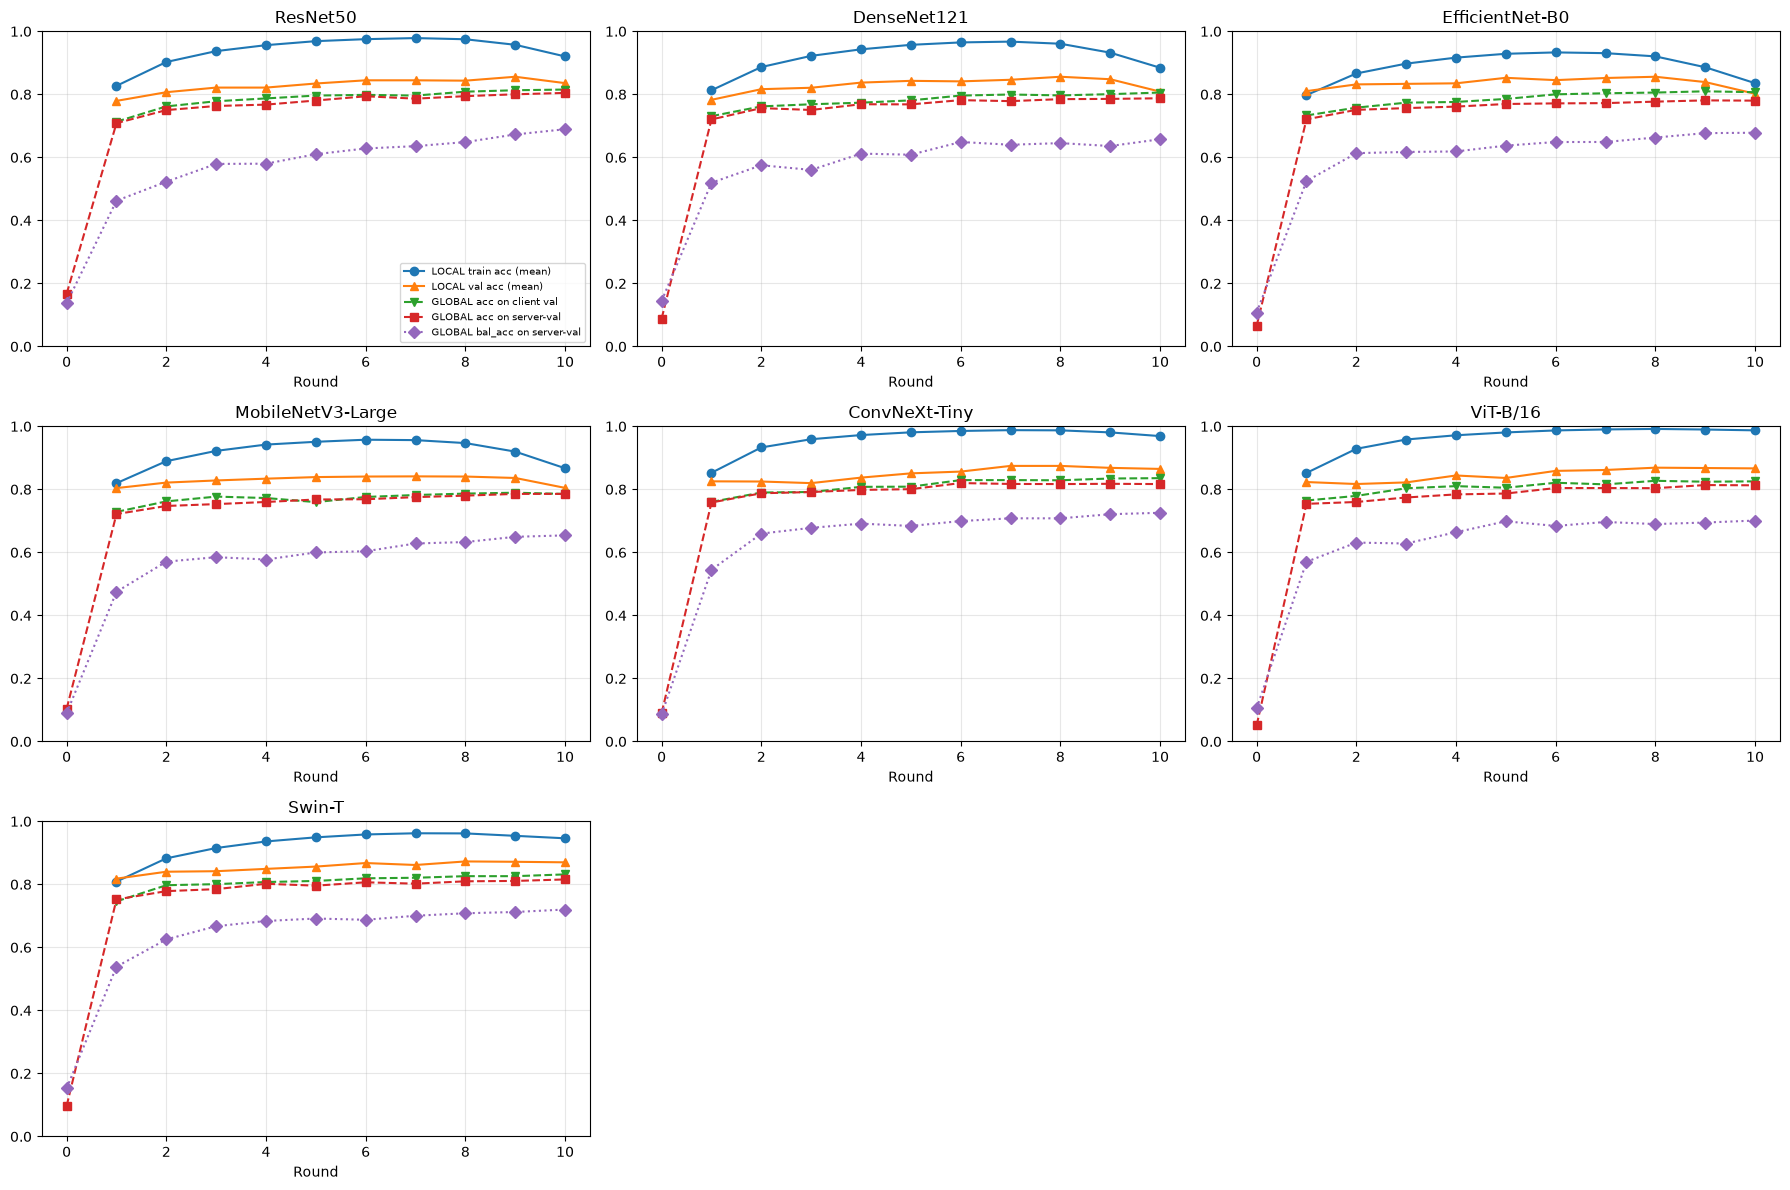

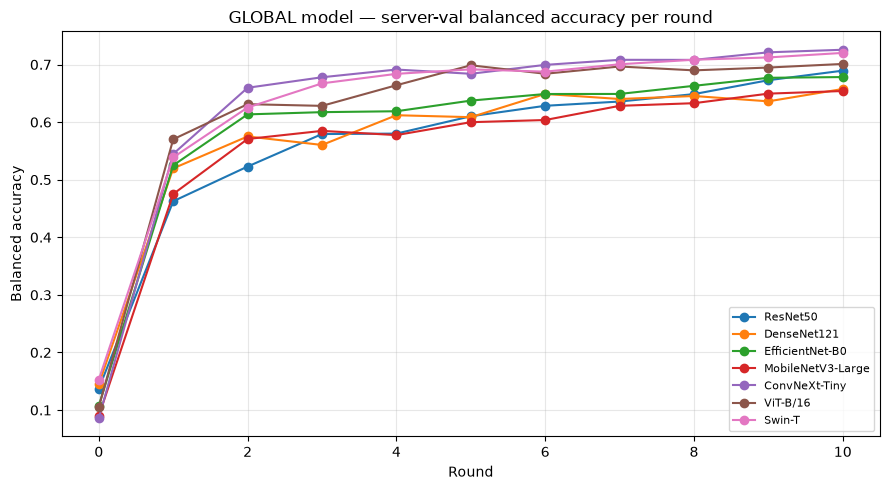

In [13]:
# Load results of every successfully finished model (also from earlier sessions).
# A history JSON is written only when a model finishes, so failed/partial runs are excluded.
DONE = [n for n in MODEL_ZOO if (OUTPUT_DIR / f"{n}_history.json").exists()]
for name in DONE:
    HISTORY[name] = json.load(open(OUTPUT_DIR / f"{name}_history.json"))
print("Finished models:", [DISPLAY[n] for n in DONE])

ncol = 3
nrow = math.ceil(len(DONE) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 4 * nrow), squeeze=False)
for ax, name in zip(axes.flat, DONE):
    h = pd.DataFrame(HISTORY[name])
    hr = h[h["round"] > 0]
    ax.plot(hr["round"], hr["local_train_acc"], "-o", label="LOCAL train acc (mean)")
    ax.plot(hr["round"], hr["local_val_acc"], "-^", label="LOCAL val acc (mean)")
    ax.plot(hr["round"], hr["global_client_val_acc"], "--v", label="GLOBAL acc on client val")
    ax.plot(h["round"], h["acc"], "--s", label="GLOBAL acc on server-val")
    ax.plot(h["round"], h["bal_acc"], ":D", label="GLOBAL bal_acc on server-val")
    ax.set_title(DISPLAY[name]); ax.set_xlabel("Round"); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
for ax in list(axes.flat)[len(DONE):]:
    ax.axis("off")
axes.flat[0].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "fl_learning_curves_all_models.png", dpi=150); plt.show()

# All models together: GLOBAL balanced accuracy on server-val per round
plt.figure(figsize=(9, 5))
for name in DONE:
    h = pd.DataFrame(HISTORY[name])
    plt.plot(h["round"], h["bal_acc"], marker="o", label=DISPLAY[name])
plt.xlabel("Round"); plt.ylabel("Balanced accuracy"); plt.grid(alpha=0.3)
plt.gca().xaxis.set_major_locator(MaxNLocator(integer=True))
plt.title("GLOBAL model — server-val balanced accuracy per round"); plt.legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "global_bal_acc_all_models.png", dpi=150); plt.show()

## 14. Final held-out test evaluation of every GLOBAL model (weights from its best round)

In [14]:
test_loader = make_loader(TEST_RECORDS, train=False)
summary, test_probs = [], {}
for name in DONE:
    ckpt = OUTPUT_DIR / f"{name}_best.pt"
    if not ckpt.exists():
        continue
    model = build_model(name, NUM_CLASSES)
    model.load_state_dict(torch.load(ckpt, map_location="cpu"))
    loss, y_test, p = predict(model, test_loader, DEVICE)
    test_probs[name] = p
    m = compute_metrics(y_test, p, NUM_CLASSES)
    best_round = max(HISTORY[name][1:], key=lambda r: r["bal_acc"])["round"]
    params = sum(t.numel() for t in model.parameters()) / 1e6
    summary.append({"model": DISPLAY[name], "params_M": round(params, 1),
                    "best_round": int(best_round), "test_loss": loss, **m})
    print(f"\n==== {DISPLAY[name]} (best round {int(best_round)}) ====")
    print(classification_report(y_test, p.argmax(1), target_names=CLASS_NAMES, digits=4, zero_division=0))
    del model
    gc.collect()

summary_df = (pd.DataFrame(summary).set_index("model")
              .sort_values("bal_acc", ascending=False).round(4))
summary_df.to_csv(OUTPUT_DIR / "test_summary_all_models.csv")
summary_df

c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)



==== ResNet50 (best round 10) ====
              precision    recall  f1-score   support

          AK     0.5676    0.6069    0.5866       173
         BCC     0.8383    0.7639    0.7994       665
         BKL     0.6485    0.5200    0.5772       525
          DF     0.7632    0.6042    0.6744        48
         MEL     0.7131    0.6903    0.7015       904
          NV     0.8548    0.9216    0.8869      2575
         SCC     0.5462    0.5159    0.5306       126
        VASC     0.8723    0.8039    0.8367        51

    accuracy                         0.7930      5067
   macro avg     0.7255    0.6783    0.6992      5067
weighted avg     0.7878    0.7930    0.7886      5067



c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)



==== DenseNet121 (best round 10) ====
              precision    recall  f1-score   support

          AK     0.5642    0.5838    0.5739       173
         BCC     0.8252    0.7383    0.7794       665
         BKL     0.7257    0.3981    0.5141       525
          DF     0.7297    0.5625    0.6353        48
         MEL     0.6972    0.6903    0.6937       904
          NV     0.8315    0.9332    0.8794      2575
         SCC     0.4656    0.4841    0.4747       126
        VASC     0.8269    0.8431    0.8350        51

    accuracy                         0.7813      5067
   macro avg     0.7083    0.6542    0.6732      5067
weighted avg     0.7765    0.7813    0.7721      5067



c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)


...

c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)



==== ViT-B/16 (best round 10) ====
              precision    recall  f1-score   support

          AK     0.6541    0.6012    0.6265       173
         BCC     0.8109    0.8060    0.8084       665
         BKL     0.7850    0.4800    0.5957       525
          DF     0.7083    0.7083    0.7083        48
         MEL     0.7085    0.7611    0.7339       904
          NV     0.8649    0.9200    0.8916      2575
         SCC     0.5935    0.5794    0.5863       126
        VASC     0.9111    0.8039    0.8542        51

    accuracy                         0.8086      5067
   macro avg     0.7546    0.7075    0.7256      5067
weighted avg     0.8067    0.8086    0.8031      5067



c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.pin_memory() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:48.)
  return data.pin_memory(device)
c:\Users\USER\anaconda3\envs\fl-isic\Lib\site-packages\torch\utils\data\_utils\pin_memory.py:57: DeprecationWarning: The argument 'device' of Tensor.is_pinned() is deprecated. Please do not pass this argument. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\aten\src\ATen\native\Memory.cpp:33.)
  return data.pin_memory(device)



==== Swin-T (best round 10) ====
              precision    recall  f1-score   support

          AK     0.6194    0.5549    0.5854       173
         BCC     0.8399    0.8045    0.8218       665
         BKL     0.7052    0.5924    0.6439       525
          DF     0.6735    0.6875    0.6804        48
         MEL     0.7225    0.7777    0.7491       904
          NV     0.8875    0.9134    0.9003      2575
         SCC     0.6161    0.5476    0.5798       126
        VASC     0.8600    0.8431    0.8515        51

    accuracy                         0.8174      5067
   macro avg     0.7405    0.7151    0.7265      5067
weighted avg     0.8147    0.8174    0.8151      5067



,params_M,best_round,test_loss,acc,bal_acc,f1_macro,auc_macro
model,,,,,,,
Swin-T,27.5,10,0.7467,0.8174,0.7151,0.7265,0.9502
ConvNeXt-Tiny,27.8,10,0.7502,0.8249,0.7109,0.7358,0.9446
ViT-B/16,85.8,10,0.8075,0.8086,0.7075,0.7256,0.9191
ResNet50,23.5,10,0.8341,0.7930,0.6783,0.6992,0.9298
EfficientNet-B0,4.0,10,0.8262,0.7902,0.6733,0.6832,0.9346
DenseNet121,7.0,10,0.8287,0.7813,0.6542,0.6732,0.9313
MobileNetV3-Large,4.2,10,0.8972,0.7792,0.6506,0.6617,0.9312


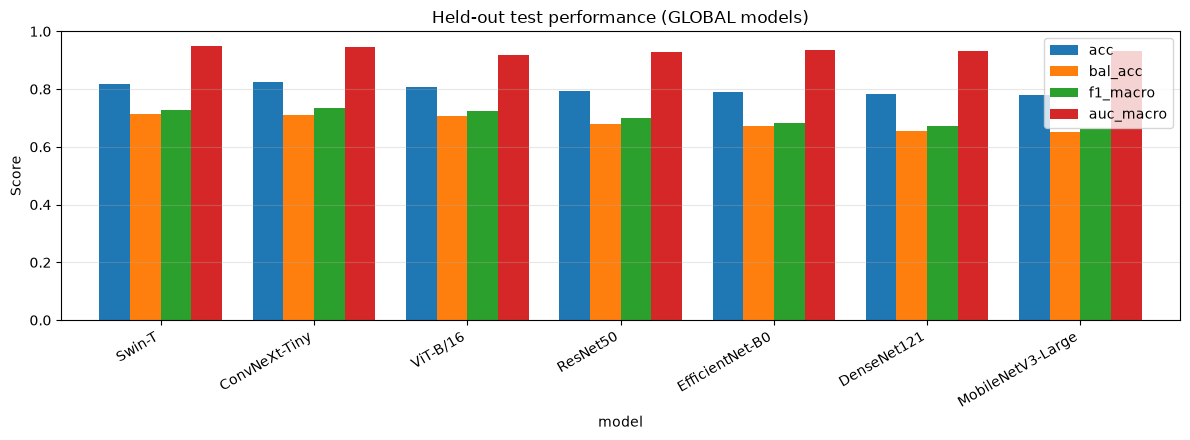

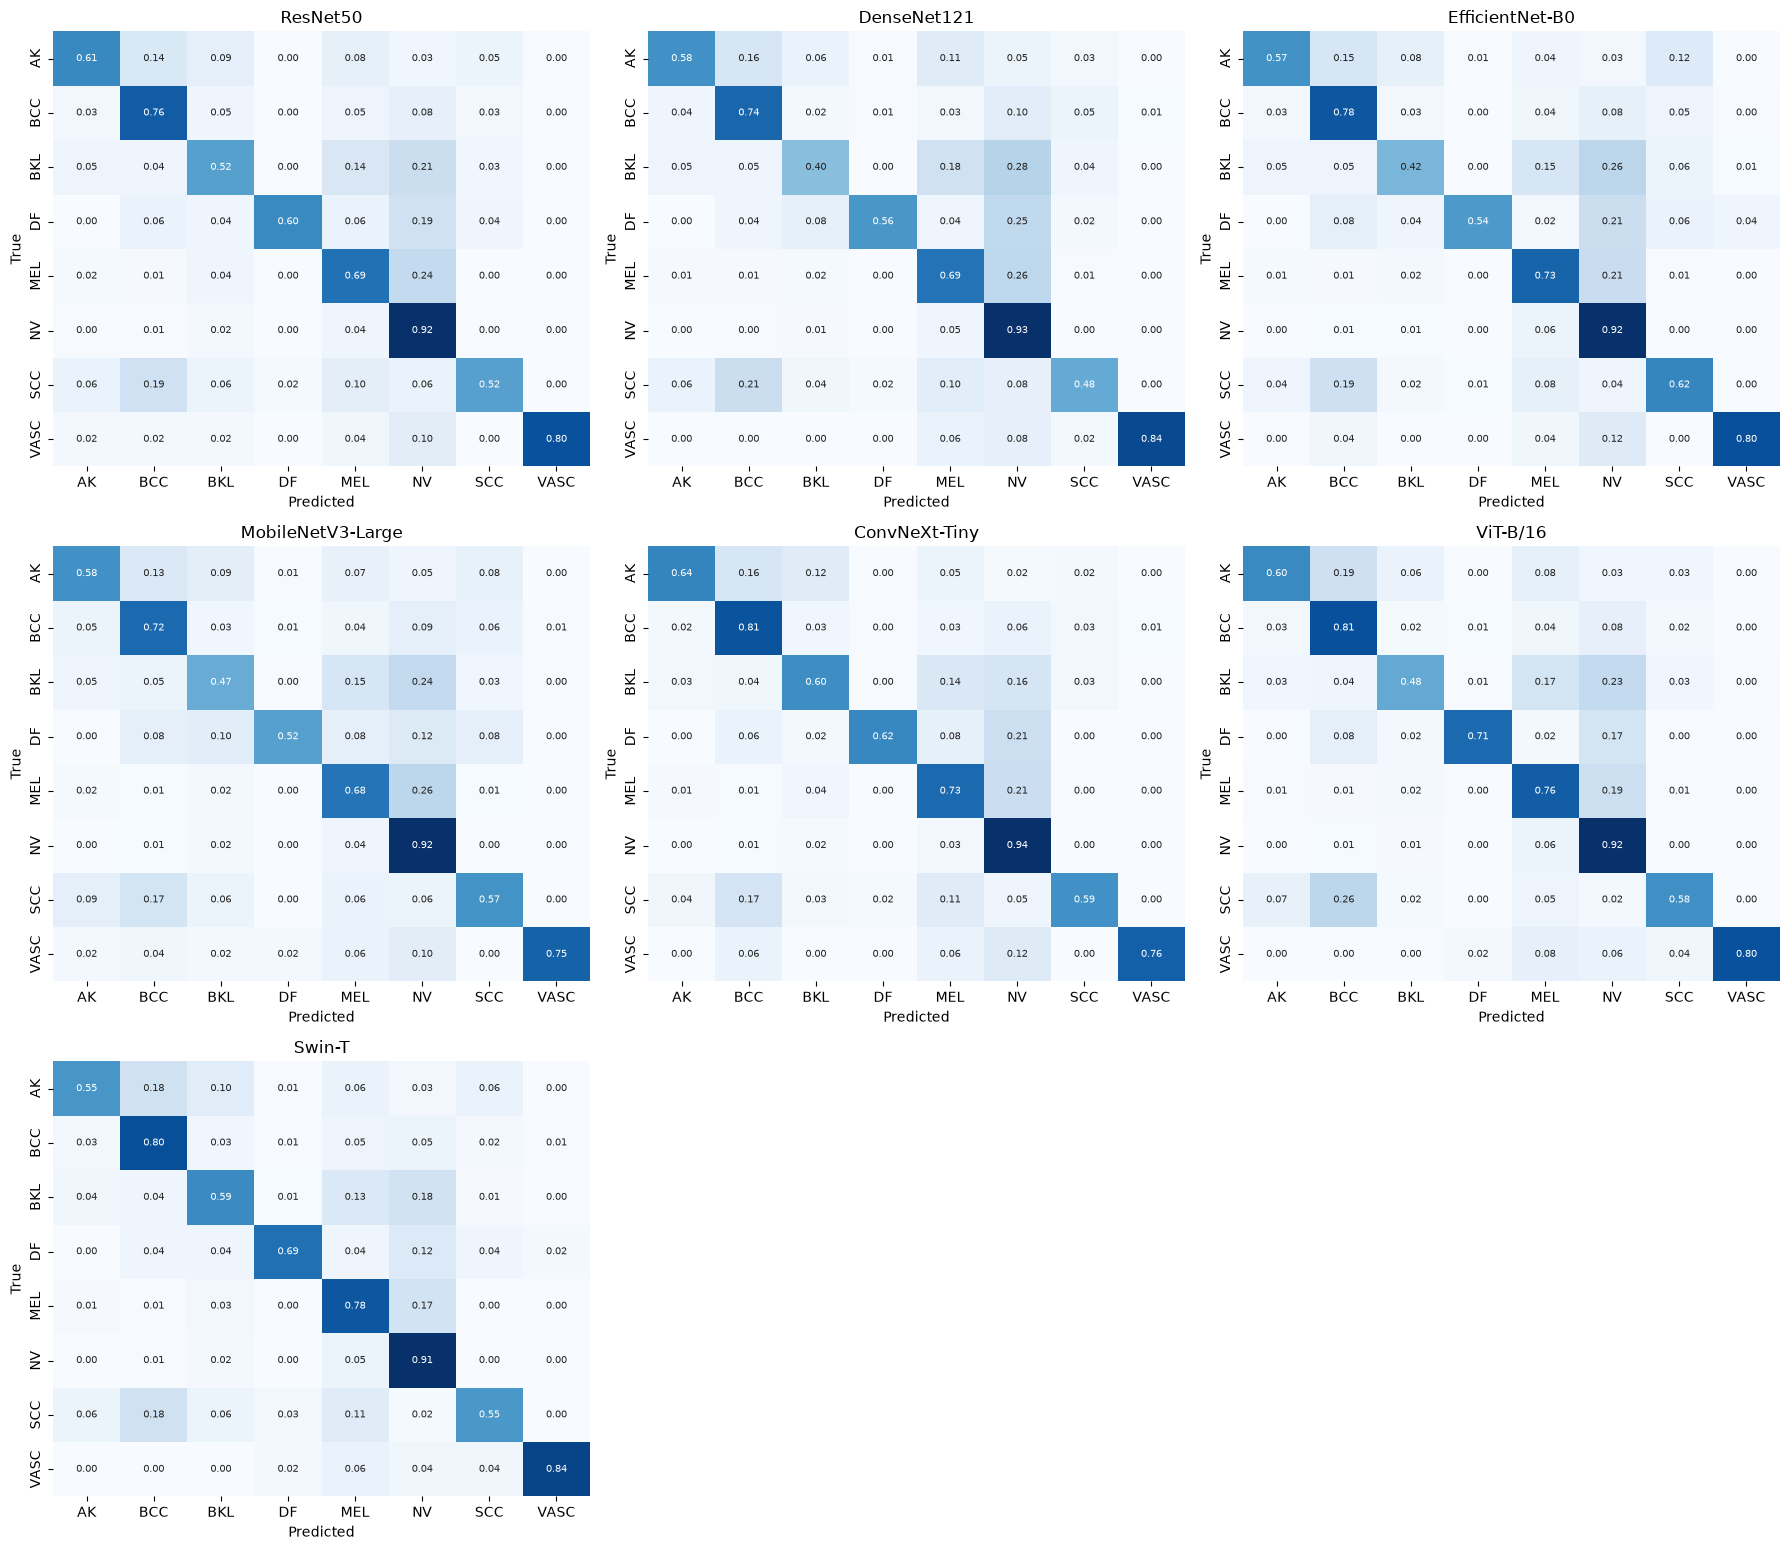

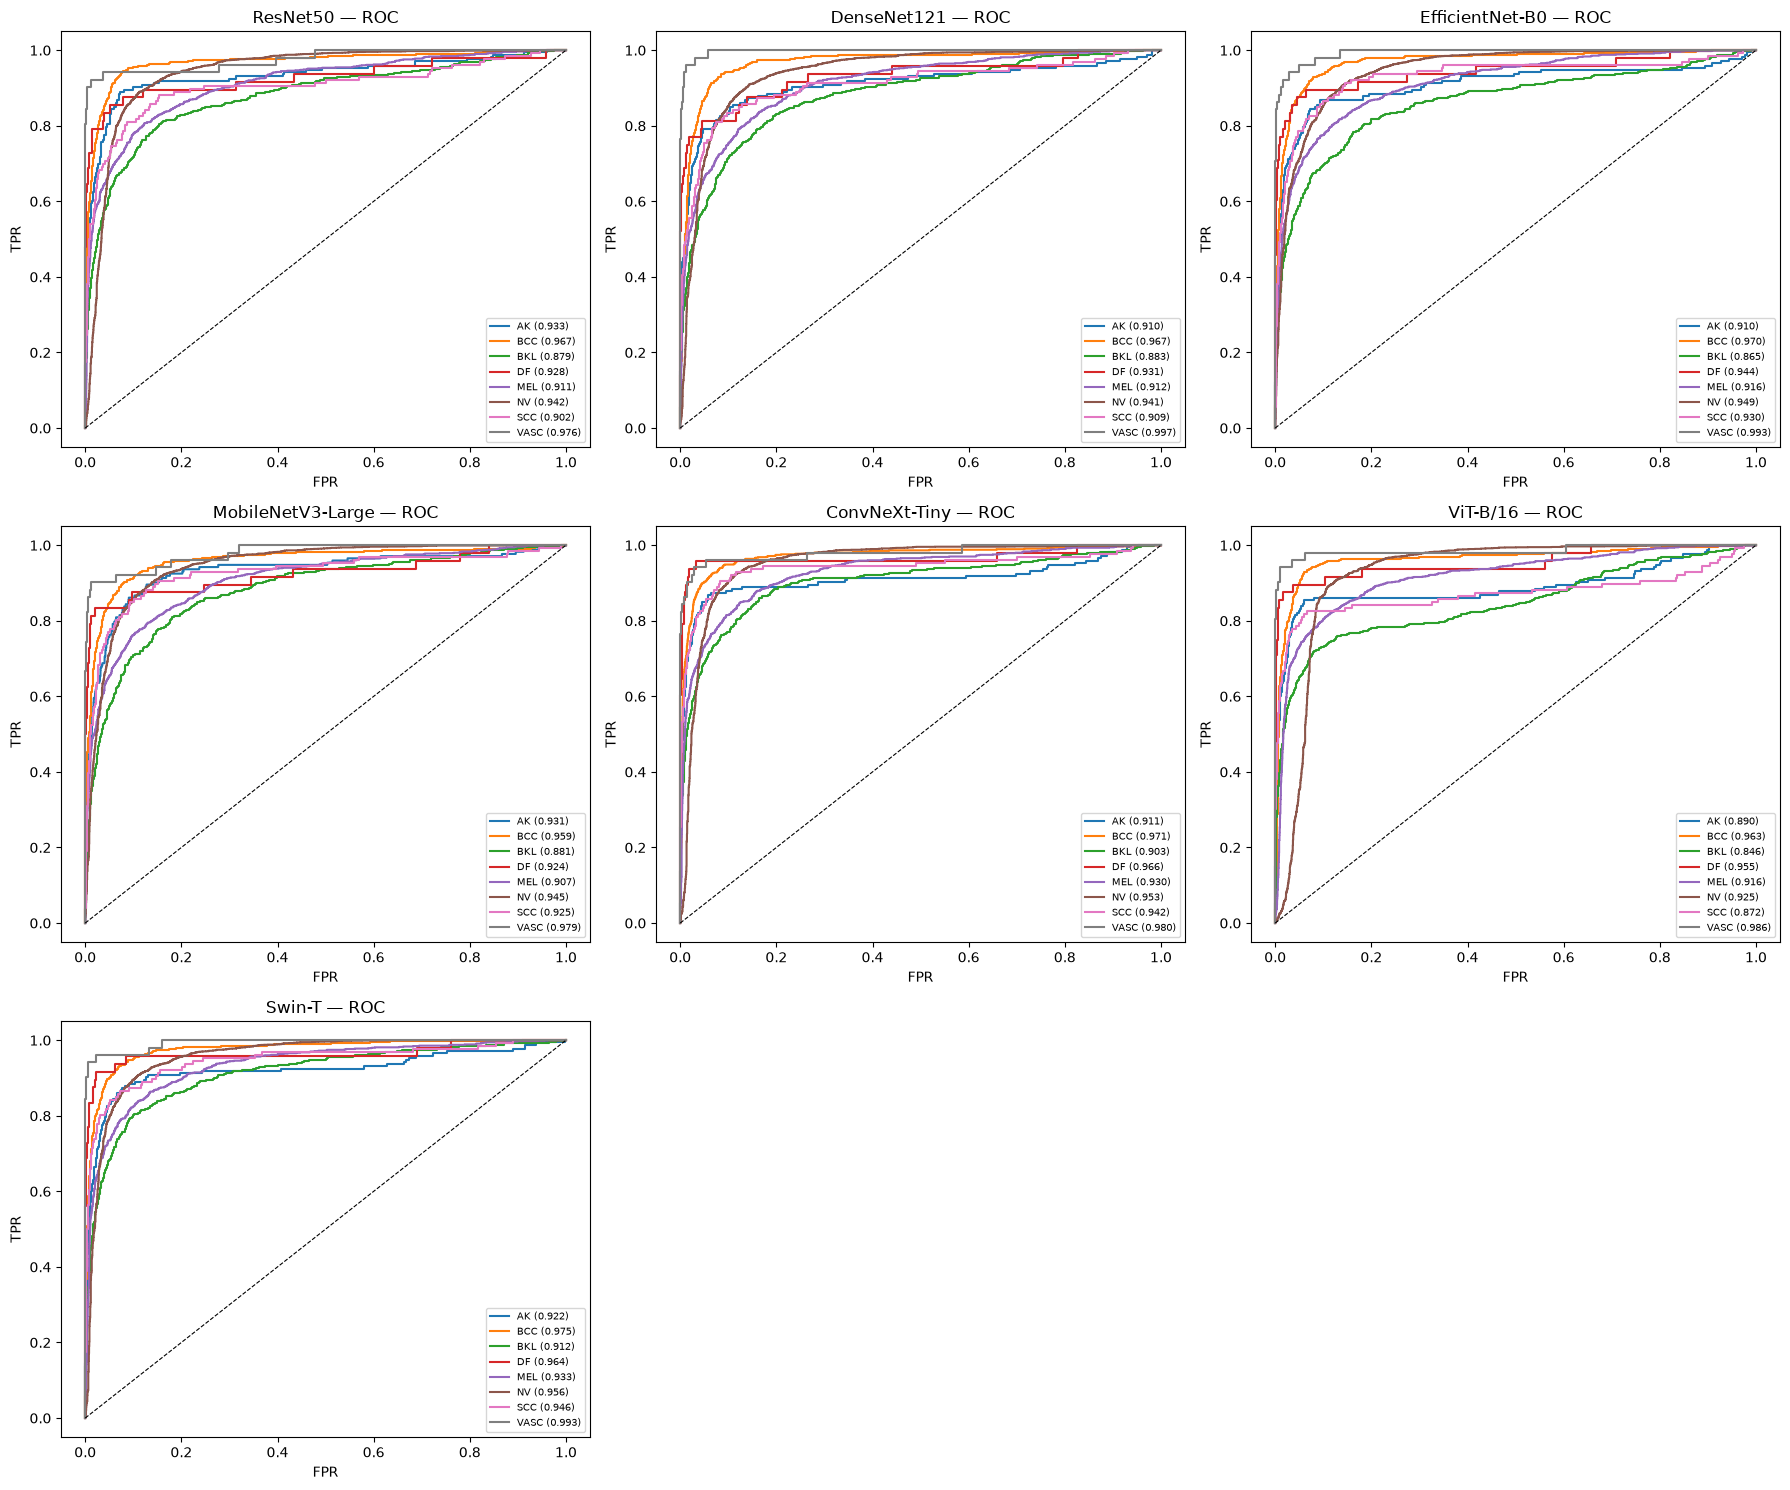

All outputs saved in: F:\Rakib\fl_isic_outputs_version2


In [15]:
# Bar chart: test metrics of all models
ax = summary_df[["acc", "bal_acc", "f1_macro", "auc_macro"]].plot.bar(figsize=(12, 4.5), width=0.8)
ax.set_ylim(0, 1); ax.set_ylabel("Score"); ax.set_title("Held-out test performance (GLOBAL models)")
ax.grid(axis="y", alpha=0.3); plt.xticks(rotation=30, ha="right")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "test_comparison_all_models.png", dpi=150); plt.show()

# Normalized confusion matrices (grid)
names = list(test_probs)
nrow = math.ceil(len(names) / ncol)
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 5.2 * nrow), squeeze=False)
for ax, name in zip(axes.flat, names):
    cm = confusion_matrix(y_test, test_probs[name].argmax(1), labels=range(NUM_CLASSES), normalize="true")
    sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", ax=ax, cbar=False, annot_kws={"size": 7},
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
    ax.set_title(f"{DISPLAY[name]}"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for ax in list(axes.flat)[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "confusion_matrices_all_models.png", dpi=150); plt.show()

# One-vs-rest ROC curves (grid)
fig, axes = plt.subplots(nrow, ncol, figsize=(6 * ncol, 5 * nrow), squeeze=False)
for ax, name in zip(axes.flat, names):
    p = test_probs[name]
    for c in range(NUM_CLASSES):
        if (y_test == c).any():
            fpr, tpr, _ = roc_curve(y_test == c, p[:, c])
            ax.plot(fpr, tpr, label=f"{CLASS_NAMES[c]} ({auc(fpr, tpr):.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=0.8)
    ax.set_title(f"{DISPLAY[name]} — ROC"); ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=7)
for ax in list(axes.flat)[len(names):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig(OUTPUT_DIR / "roc_curves_all_models.png", dpi=150); plt.show()

print("All outputs saved in:", OUTPUT_DIR.resolve())